# Traffic file analysis: ground speed

This notebook focuses on describing ground speed as aircraft approach an airport for landing, or take off from it.

In [1]:
## Imports


import pandas as pd
import io
import numpy as np
from pitot.geodesy import distance

from traffic.core import Traffic

from pitot.geodesy import distance

import vaex
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [16, 9]
plt.rcParams['figure.dpi'] = 150

NM_TO_METERS = 1852

## Select data file

import ipywidgets as widgets

fileImport = widgets.FileUpload(accept='',multiple=False)
fileImport

FileUpload(value=(), description='Upload')

In [2]:
## Parse traffic

tr = Traffic(pd.read_parquet(io.BytesIO(fileImport.value[0].content)))


In [4]:
from traffic.data import airports
airport = airports['EGLL']
landers = set(tr.landing_at(airport).eval(8).flight_ids)
tr = tr.cumulative_distance().distance(airport).eval(8).airborne()
assert tr is not None

In [5]:
vdf = vaex.from_pandas(tr.data)
vdf['landing'] = vdf.flight_id.isin(landers)
vdf

could not convert column squawk, error: TypeError('boolean value of NA is ambiguous'), will try to convert it to string


#,timestamp,icao24,latitude,longitude,groundspeed,track,vertical_rate,callsign,onground,alert,spi,squawk,altitude,geoaltitude,last_position,lastcontact,serials,hour,flight_id,cumdist,compute_gs,compute_track,distance,landing
0,"Timestamp('2025-10-29 05:50:06+0000', tz='UTC')",a9a399,52.80162048339844,-2.462310791015625,436.0,133.69804732742114,-1792.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32650.0,32325.0,1761717005.937,1761717005.999,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,0.0,436.6887733493137,132.86349083087984,108.95969476569981,np.True_
1,"Timestamp('2025-10-29 05:50:07+0000', tz='UTC')",a9a399,52.80024719238281,-2.459869384765625,435.0,133.78905004035772,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32625.0,32300.0,1761717006.998,1761717007.0,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,0.12130243704147603,436.6887733493137,132.86349083087984,108.83862507174055,np.True_
2,"Timestamp('2025-10-29 05:50:08+0000', tz='UTC')",a9a399,52.798828125,-2.4575042724609375,434.0,133.69380790608125,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32575.0,32275.0,1761717007.989,1761717007.996,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,0.2425044157956242,436.3271235149335,134.70951381249702,108.71747698646195,np.True_
3,"Timestamp('2025-10-29 05:50:09+0000', tz='UTC')",a9a399,52.79759293895656,-2.455365862165138,434.0,133.69380790608125,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32550.0,32250.0,1761717008.986,1761717008.987,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,0.35008679649444036,387.29657051573815,133.6201903630773,108.61002325075509,np.True_
4,"Timestamp('2025-10-29 05:50:10+0000', tz='UTC')",a9a399,52.79621887207031,-2.4529266357421875,434.0,133.69380790608125,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32525.0,32200.0,1761717009.854,1761717009.998,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,0.4713687671570004,436.6150943852162,132.90248946009558,108.48897073847641,np.True_
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1,961,073","Timestamp('2025-10-29 12:17:54+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,np.True_
"1,961,074","Timestamp('2025-10-29 12:17:55+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,np.True_
"1,961,075","Timestamp('2025-10-29 12:17:56+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,np.True_
"1,961,076","Timestamp('2025-10-29 12:17:57+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,np.True_


In [6]:
max_dist = vdf.groupby('flight_id', agg=vaex.agg.max('cumdist'))
vdf['max_dist'] = vdf.flight_id.map(
    dict(zip(max_dist['flight_id'].tolist(), max_dist['cumdist_max'].tolist()))
)

vdf['cumdist'] = vdf.cumdist - vdf.max_dist * vdf.landing
vdf

#,timestamp,icao24,latitude,longitude,groundspeed,track,vertical_rate,callsign,onground,alert,spi,squawk,altitude,geoaltitude,last_position,lastcontact,serials,hour,flight_id,cumdist,compute_gs,compute_track,distance,landing,max_dist
0,"Timestamp('2025-10-29 05:50:06+0000', tz='UTC')",a9a399,52.80162048339844,-2.462310791015625,436.0,133.69804732742114,-1792.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32650.0,32325.0,1761717005.937,1761717005.999,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,-175.53593017711532,436.6887733493137,132.86349083087984,108.95969476569981,np.True_,175.53593017711532
1,"Timestamp('2025-10-29 05:50:07+0000', tz='UTC')",a9a399,52.80024719238281,-2.459869384765625,435.0,133.78905004035772,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32625.0,32300.0,1761717006.998,1761717007.0,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,-175.41462774007385,436.6887733493137,132.86349083087984,108.83862507174055,np.True_,175.53593017711532
2,"Timestamp('2025-10-29 05:50:08+0000', tz='UTC')",a9a399,52.798828125,-2.4575042724609375,434.0,133.69380790608125,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32575.0,32275.0,1761717007.989,1761717007.996,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,-175.2934257613197,436.3271235149335,134.70951381249702,108.71747698646195,np.True_,175.53593017711532
3,"Timestamp('2025-10-29 05:50:09+0000', tz='UTC')",a9a399,52.79759293895656,-2.455365862165138,434.0,133.69380790608125,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32550.0,32250.0,1761717008.986,1761717008.987,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,-175.18584338062087,387.29657051573815,133.6201903630773,108.61002325075509,np.True_,175.53593017711532
4,"Timestamp('2025-10-29 05:50:10+0000', tz='UTC')",a9a399,52.79621887207031,-2.4529266357421875,434.0,133.69380790608125,-1728.0,AAL100,np.False_,np.False_,np.False_,np.bytes_(b'5157'),32525.0,32200.0,1761717009.854,1761717009.998,"'array([-1408128977, -1408236086, -1408128773, ...","Timestamp('2025-10-29 05:00:00+0000', tz='UTC')",AAL100_1235,-175.06456140995832,436.6150943852162,132.90248946009558,108.48897073847641,np.True_,175.53593017711532
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1,961,073","Timestamp('2025-10-29 12:17:54+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,0.0,0.0,180.0,1.1395757590945181,np.True_,137.15359044419358
"1,961,074","Timestamp('2025-10-29 12:17:55+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,0.0,0.0,180.0,1.1395757590945181,np.True_,137.15359044419358
"1,961,075","Timestamp('2025-10-29 12:17:56+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,0.0,0.0,180.0,1.1395757590945181,np.True_,137.15359044419358
"1,961,076","Timestamp('2025-10-29 12:17:57+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp(

/home/mael/miniconda3/envs/ntraffic/lib/python3.12/site-packages/vaex/functions.py:96: RuntimeWarning: invalid value encountered in log
  result = function(*numpy_data, **kwargs)


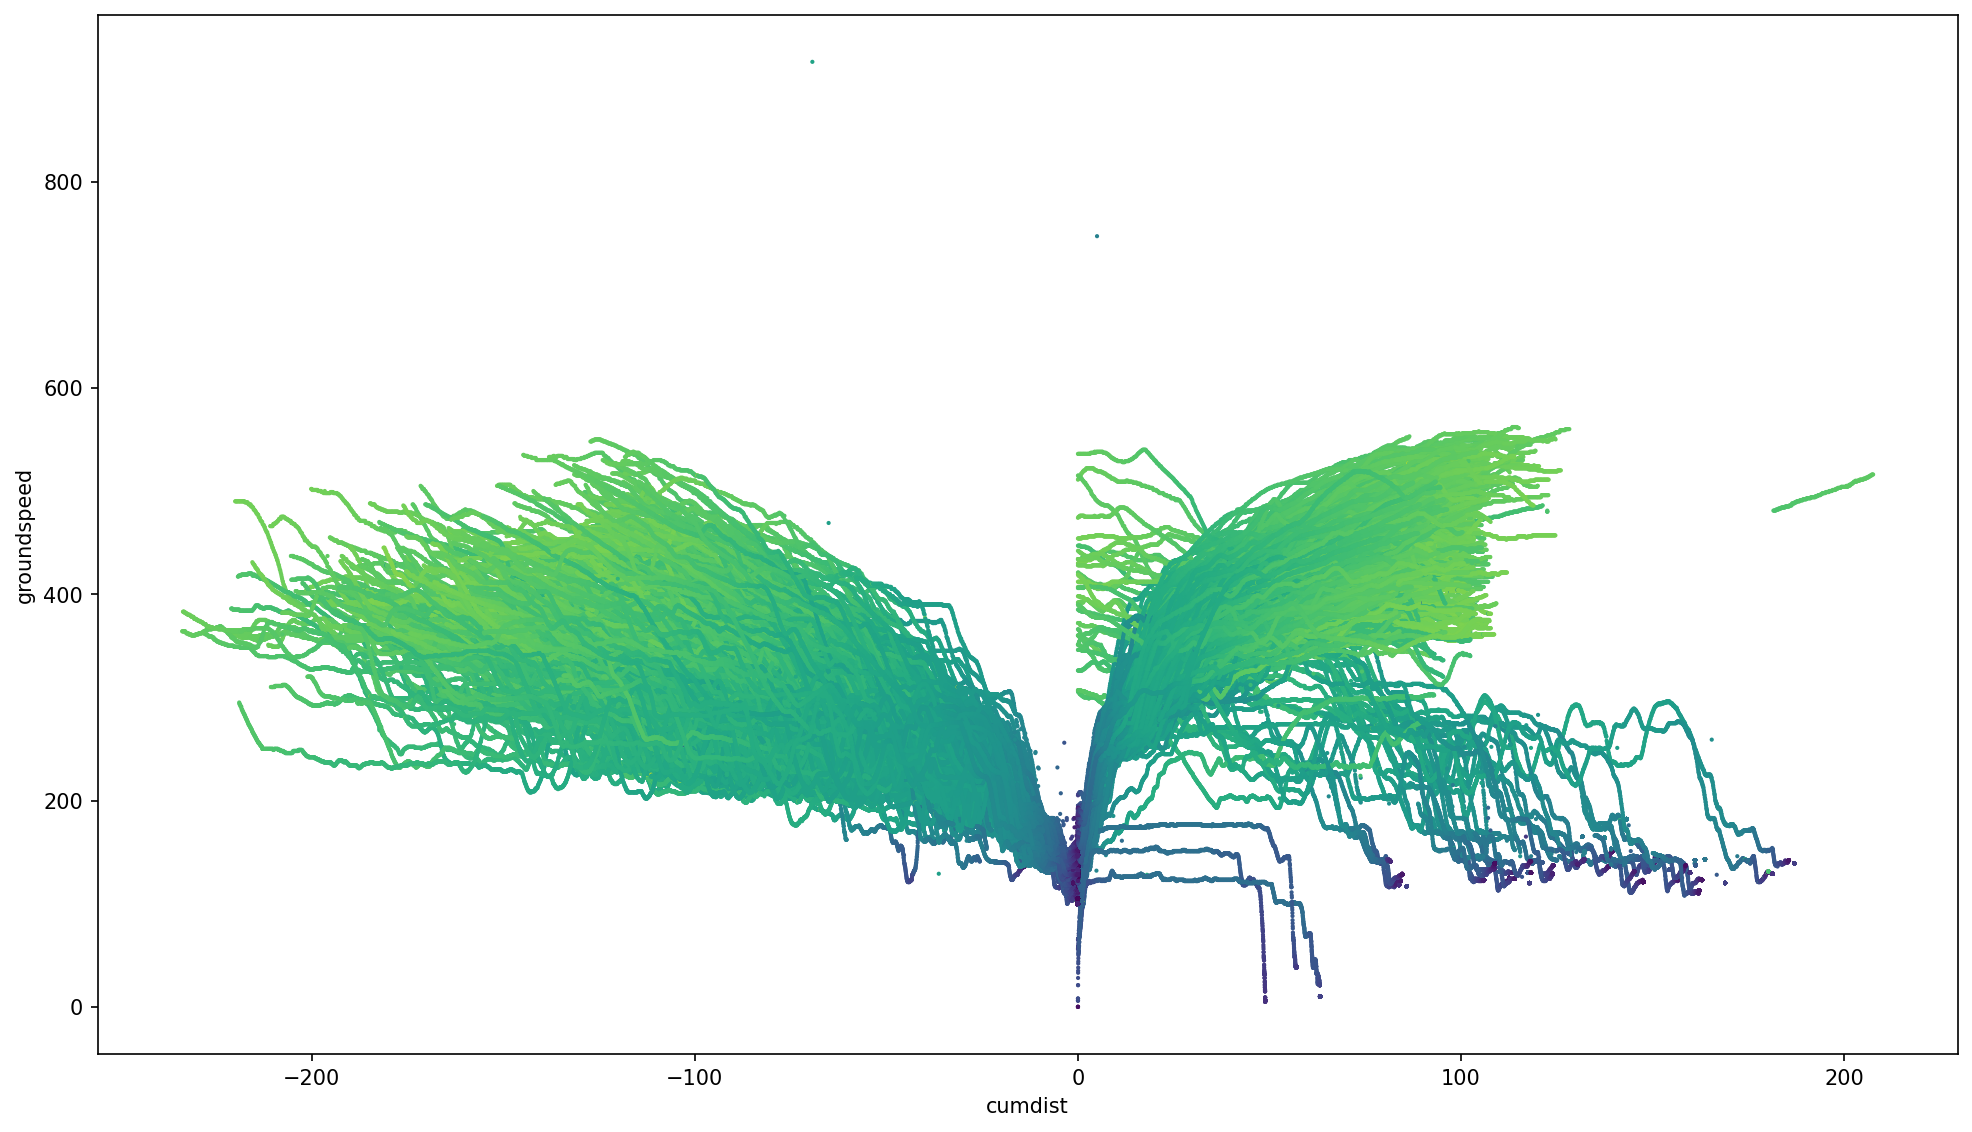

In [7]:
vdf.viz.scatter(vdf.cumdist, vdf.groundspeed,s=1,c_expr=np.log(vdf.altitude),length_check=False)

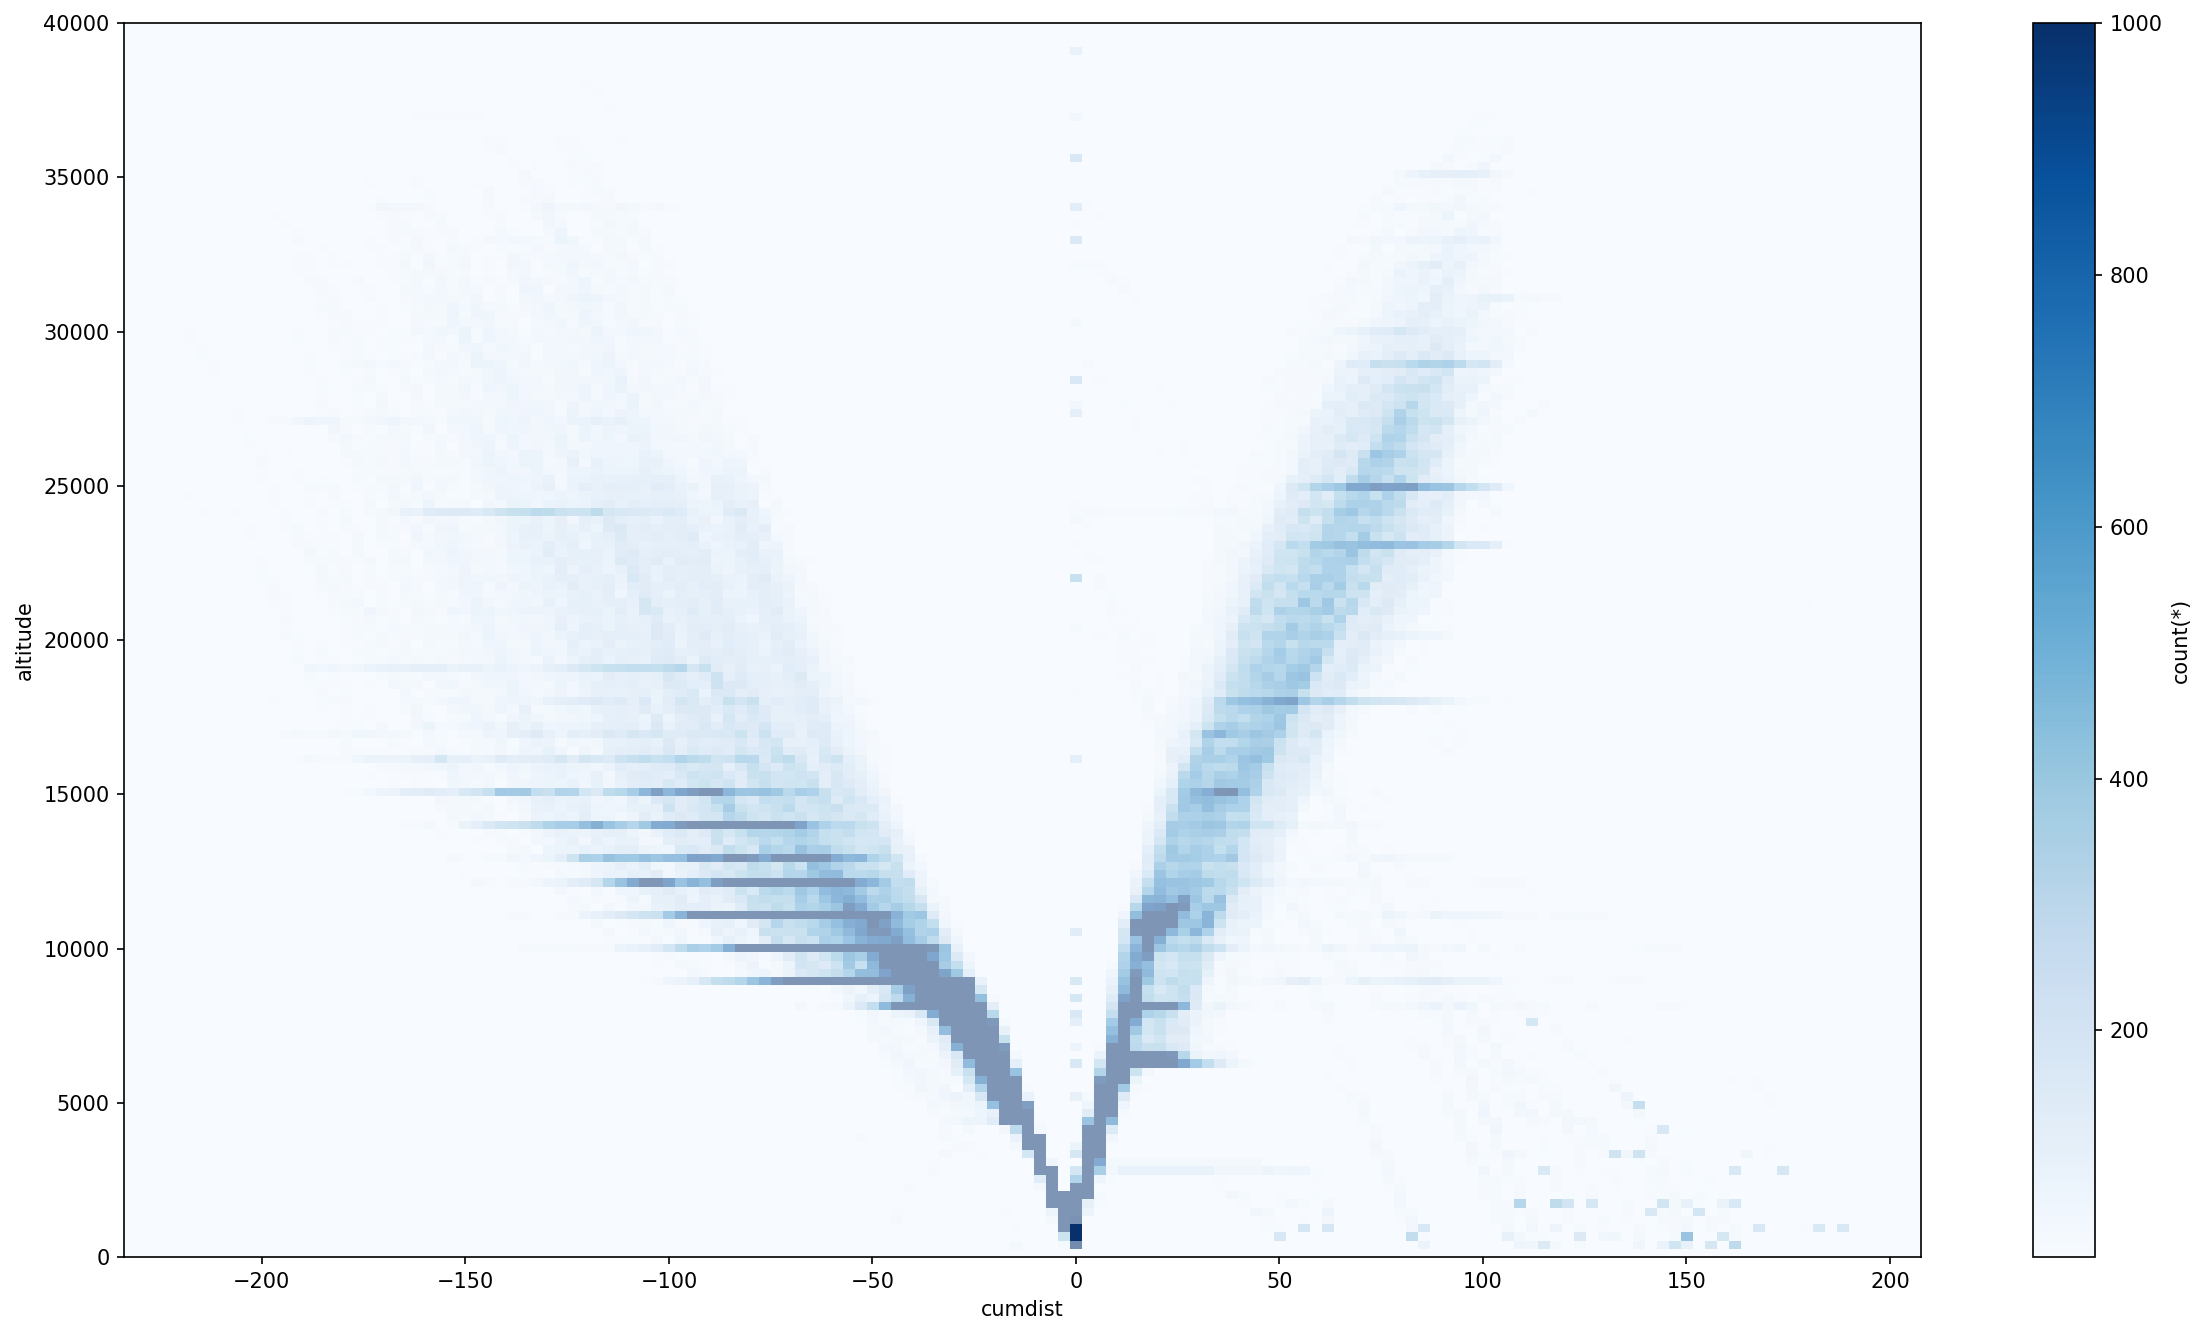

In [10]:
vdf.viz.heatmap(vdf.cumdist, vdf.altitude,limits=['minmax', [0, 40000]],shape=150,selection=[vdf.landing,~vdf.landing],colormap='Blues',vmin=20,vmax=1000)

(2, 128) (129,)
(2, 128, 128)


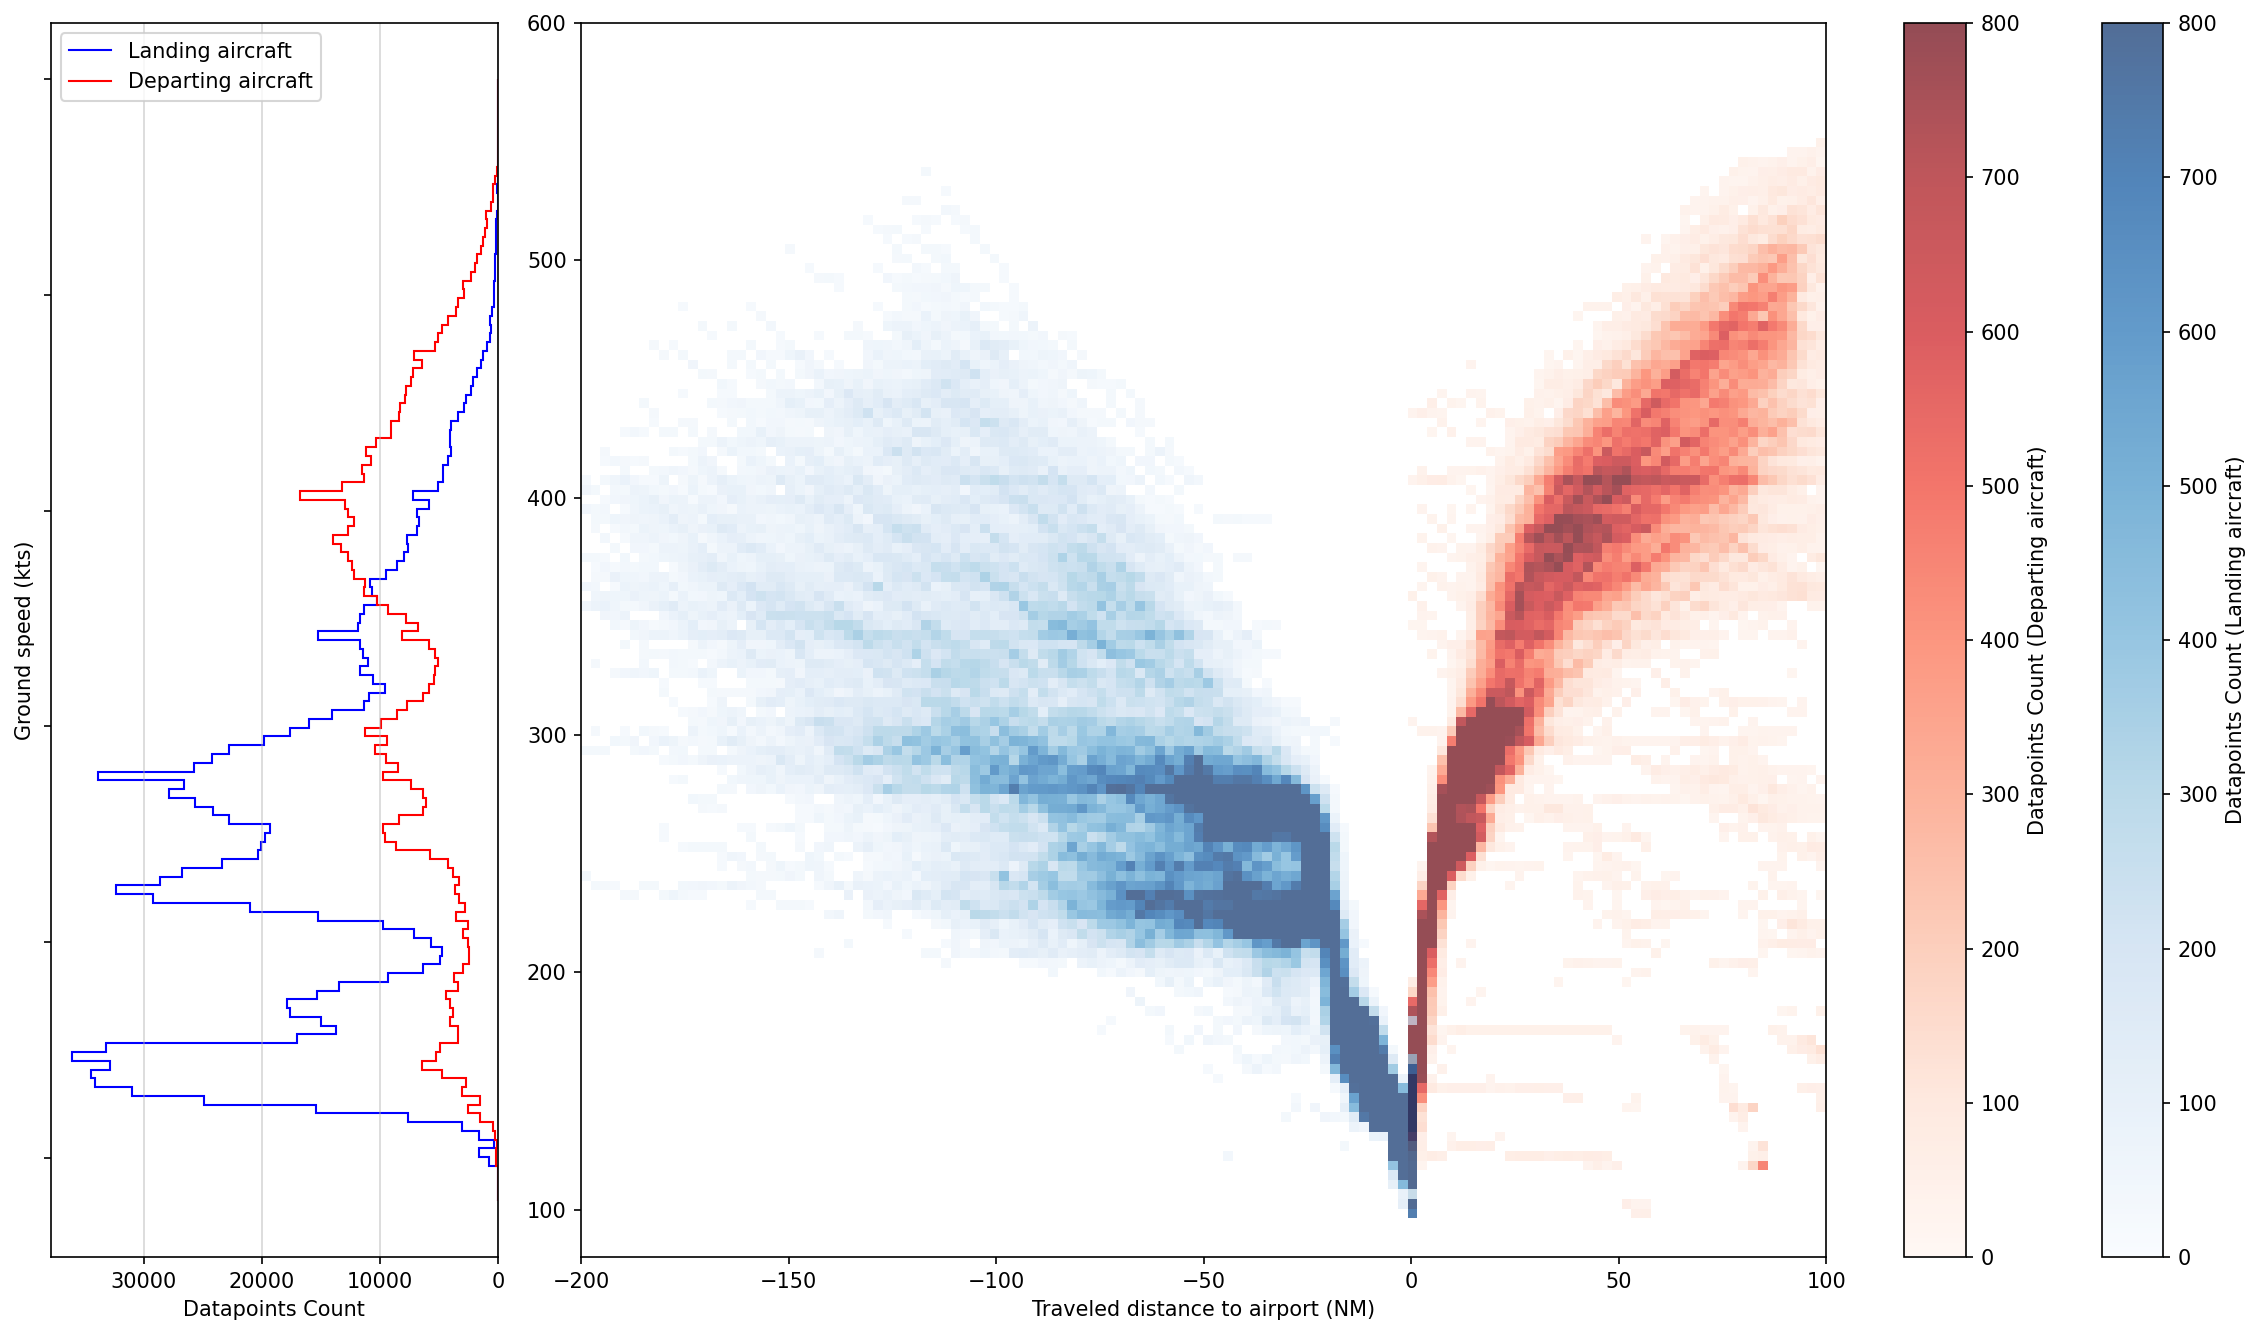

In [16]:
fig,axs = plt.subplot_mosaic([['hist','heat']],figsize=(16,9),gridspec_kw={'width_ratios':[1,4],'height_ratios':[1]})
axs['hist'].tick_params(axis='y',labelleft=False)
plt.sca(axs['hist'])
#vdf.viz.histogram(vdf.groundspeed)#,selection=[vdf.landing, ~vdf.landing,~vdf.onground])

cumdist_limits = [-200,100]

bins_per_dim = 128
limits = [80,600]
counts = vdf.count(vdf.groundspeed, selection=[vdf.landing,~vdf.landing], binby=vdf.groundspeed, limits=limits, shape=bins_per_dim)
edges = vdf.bin_edges(vdf.groundspeed, limits=limits, shape=bins_per_dim)

print(counts.shape,edges.shape)

centers = (edges[:-1] + edges[1:]) / 2
widths = np.diff(edges)

#axs['hist'].barh(centers, counts, height=widths,histtype='step')
axs['hist'].stairs(counts[0], edges, orientation='horizontal', fill=False,color='blue',label='Landing aircraft')
axs['hist'].stairs(counts[1], edges, orientation='horizontal', fill=False,color='red',label='Departing aircraft')
axs['hist'].invert_xaxis()
axs['hist'].set_xlabel('Datapoints Count')
axs['hist'].set_ylabel('Ground speed (kts)')
axs['hist'].grid(True, axis='x', alpha=0.5)
axs['hist'].legend(loc='upper left')

plt.sca(axs['heat'])
h = vdf.count(binby=['cumdist', 'groundspeed'], selection=[vdf.landing,~vdf.landing], limits=[cumdist_limits, limits], shape=bins_per_dim)
print(h.shape)
h1 = h[0]
h2 = h[1]

h1_masked = np.ma.masked_where(h1 < 20, h1)
h2_masked = np.ma.masked_where(h2 < 20, h2)

# Second heatmap
im2 = axs['heat'].imshow(
    h2_masked.T,
    origin='lower',
    extent=[cumdist_limits[0], cumdist_limits[1], limits[0], limits[1]],
    cmap='Reds',
    vmin=0,vmax=800,
    alpha=0.7,
    aspect='auto'
)

# First heatmap
im1 = axs['heat'].imshow(
    h1_masked.T,
    origin='lower',
    extent=[cumdist_limits[0], cumdist_limits[1], limits[0], limits[1]],
    cmap='Blues',
    vmin=0,vmax=800,
    alpha=0.7,
    aspect='auto'
)

cbar1 = fig.colorbar(im1, ax=axs['heat'],pad=-0.02)
cbar1.set_label('Datapoints Count (Landing aircraft)')

cbar2 = fig.colorbar(im2, ax=axs['heat'])
cbar2.set_label('Datapoints Count (Departing aircraft)')

axs['heat'].set_xlabel('Traveled distance to airport (NM)')

fig.tight_layout()


#vdf.viz.heatmap(vdf.cumdist, vdf.groundspeed, normalize=None, selection=[vdf.landing],vmin=0, vmax=150, colormap='Blues',shape=150, colorbar=True,
#                xlabel='Traveled distance (NM)', title='2D histogram of ground speed vs traveled distance')
plt.savefig('groundspeed_vs_cumdist.svg')
plt.show()

In [24]:
resampled = tr.resample('1min').eval(8)

In [53]:
from itertools import combinations

def closest_aircraft(df):
    results = []

    for timestamp, group in df.groupby("timestamp"):
        if len(group) < 2:
            continue

        # Evaluate every unique pair of aircraft
        pairs = (
            (
                distance(
                    a.latitude, a.longitude,
                    b.latitude, b.longitude,
                ),
                a.flight_id,
                b.flight_id,
            )
            for a, b in combinations(group.itertuples(index=False), 2)
        )

        min_distance, flight_id_1, flight_id_2 = min(pairs)

        results.append({
            "timestamp": timestamp,
            "flight_id_1": flight_id_1,
            "flight_id_2": flight_id_2,
            "distance": min_distance,
        })

    return pd.DataFrame(results)

closest_df = tr.data.dropna(subset=['flight_id','latitude','longitude','altitude'])
closest_df = closest_aircraft(closest_df.where(closest_df['altitude'].between(10000,20000)))


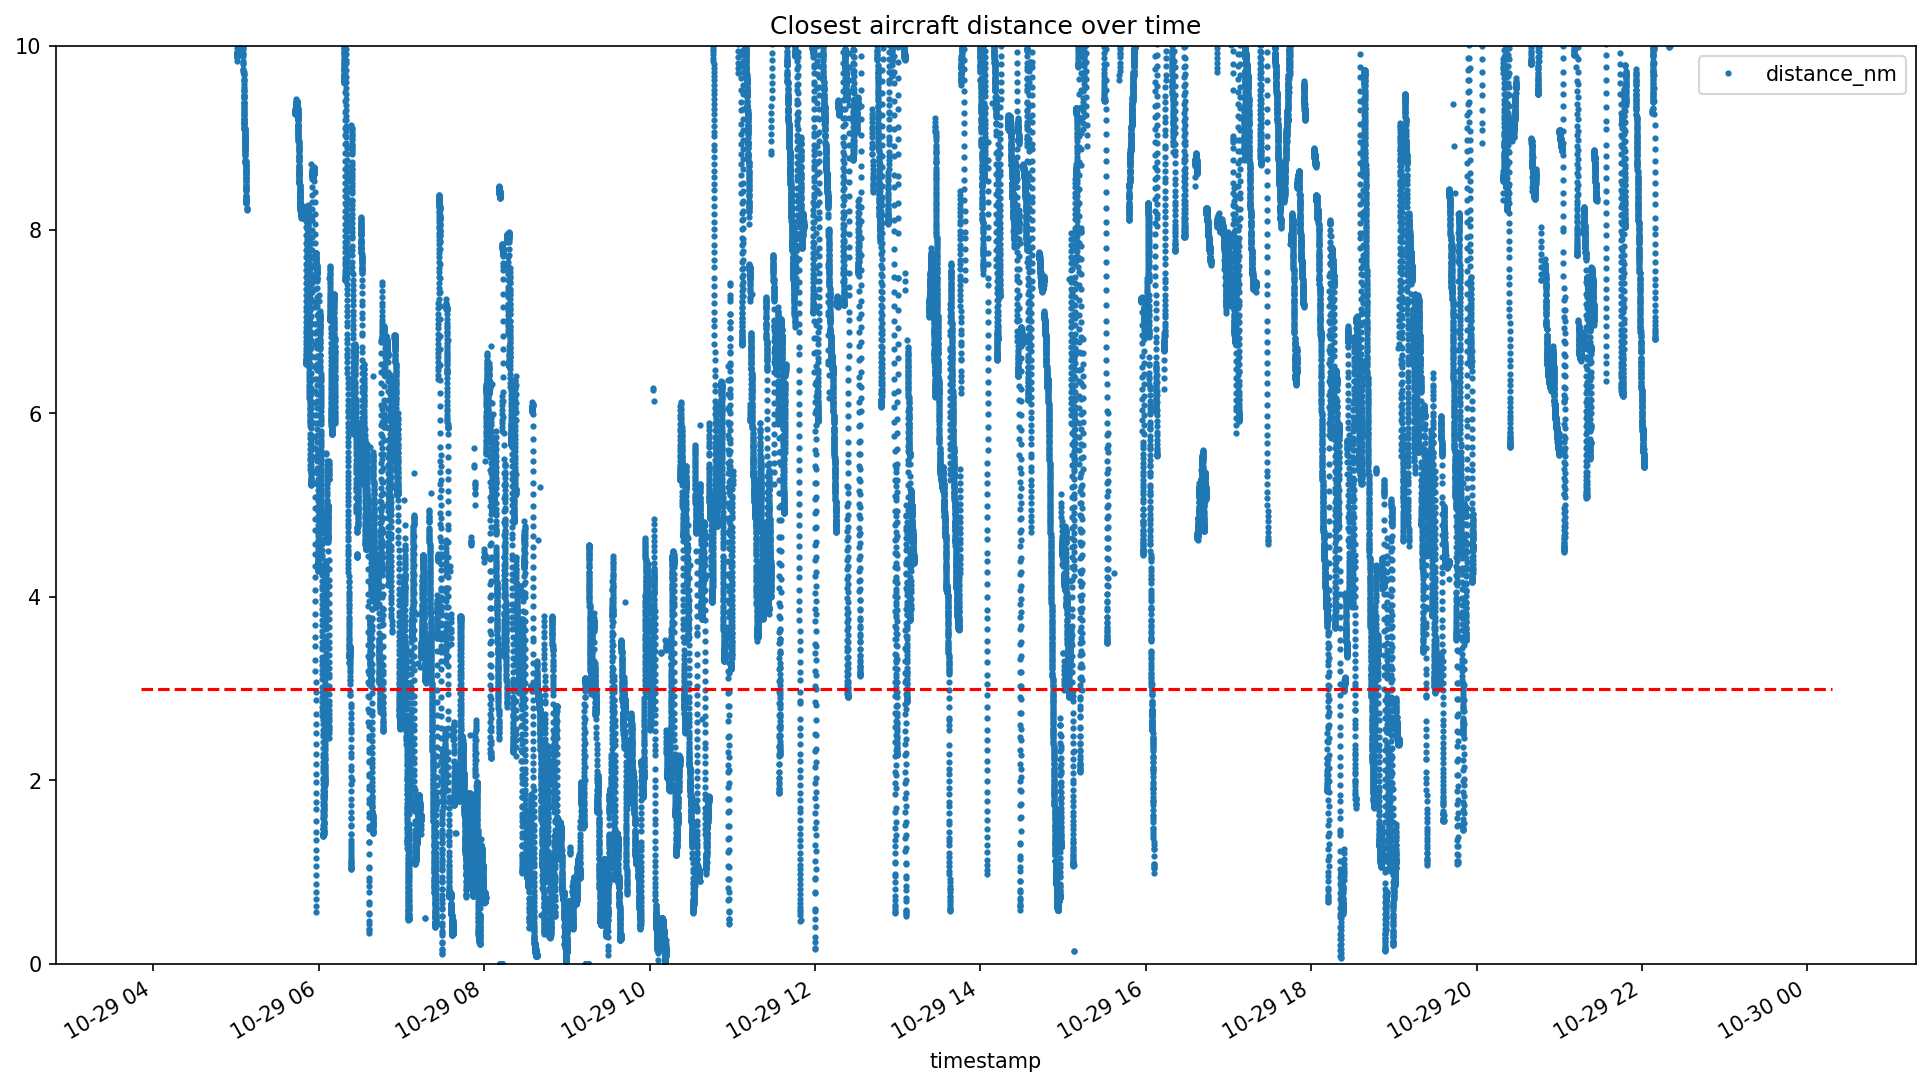

In [54]:
closest_df['distance_nm'] = closest_df['distance'] / NM_TO_METERS
ax = closest_df.plot(x='timestamp', y='distance_nm', kind='line', title='Closest aircraft distance over time',linestyle='',marker='o', markersize=2,)
ax.set_ylim(0, 10)
xlims = ax.get_xlim()
ax.hlines(y=3,xmin=xlims[0], xmax=xlims[1], color='r', linestyle='--', label='3 NM Threshold')
plt.show()